> **Solved version.** Every exercise is filled in. Try the student notebook first.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
os.chdir('..')  # run from the study folder

# 01 · BQ 101 offline: circuits, shots, statevectors, MPS

An offline remake of BlueQubit's *BQ 101: An Introduction to the BlueQubit Platform*, with exercises.

Instead of the cloud we use `LocalBQ` from `offline_sim.py`. It has the **same `run()` call** as the
real SDK, so everything you practise here works on BlueQubit by swapping one line:

```python
bq = LocalBQ()                          # offline (this notebook)
# bq = bluequbit.init(token)            # the real platform
```

| device | what it stores | returns |
|---|---|---|
| `"cpu"` | the full statevector ($2^n$ numbers) | statevector, counts, expectation values |
| `"mps.cpu"` | a matrix product state, bond dimension $\chi$ | counts, expectation values |
| `"pauli-path"` | the observable as a sum of Pauli strings | expectation values only |

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from qiskit import QuantumCircuit
from offline_sim import LocalBQ, z_sum
import checks

bq = LocalBQ()
plt.rcParams.update({"figure.dpi": 100})
print("ready")

ready


## 1. The Bell state: entanglement in two gates

$H$ on qubit 0 makes $(|0\rangle+|1\rangle)/\sqrt2$; then a CNOT copies "is qubit 0 a 1?" onto
qubit 1. Result: $(|00\rangle + |11\rangle)/\sqrt2$. Measuring gives `00` or `11`, never `01` or `10`:
the two qubits are perfectly correlated, although each alone is a fair coin. That is **entanglement**.

In [3]:
qc = QuantumCircuit(2)
qc.h(0)
qc.cx(0, 1)
print(qc.draw())

counts = bq.run(qc, shots=10_000).get_counts()     # sample 10,000 measurement outcomes
print("counts:", counts)
print("statevector:", np.round(bq.run(qc).get_statevector(), 3))   # no shots -> statevector

     ┌───┐     
q_0: ┤ H ├──■──
     └───┘┌─┴─┐
q_1: ─────┤ X ├
          └───┘
counts: {np.str_('00'): np.int64(4971), np.str_('11'): np.int64(5029)}
statevector: [0.707+0.j 0.   +0.j 0.   +0.j 0.707+0.j]


### ✏️ Exercise: read a statevector

The statevector lists amplitudes in the order `|00>, |01>, |10>, |11>` (qubit 0 is the **rightmost** bit).
Build a circuit that prepares $|01\rangle$, i.e. **qubit 0 = 1, qubit 1 = 0**, and store it as `qc_01`.
Predict which entry of the statevector is 1 before you run it.

In [4]:
qc_01 = QuantumCircuit(2)
qc_01.x(0)

# --- check (don't edit) ---
sv = bq.run(qc_01).get_statevector()
checks.close("|01> statevector", sv, [0, 1, 0, 0], hint="index 1 = binary 01 = qubit 0 set. Flip qubit 0.")
checks.equal("|01> counts key", list(bq.run(qc_01, shots=10).get_counts()), ["01"])

✅ PASS  |01> statevector
✅ PASS  |01> counts key


True

### ✏️ Exercise: uniform superposition on 3 qubits

Build `qc_uniform`, a 3-qubit circuit whose statevector is $\frac{1}{\sqrt8}(1,1,1,1,1,1,1,1)$.
This is a *product* state (no entanglement), so you need no two-qubit gates.

In [5]:
qc_uniform = QuantumCircuit(3)
qc_uniform.h(range(3))

# --- check (don't edit) ---
checks.close("uniform 3 qubits", bq.run(qc_uniform).get_statevector(), np.ones(8) / np.sqrt(8))

✅ PASS  uniform 3 qubits


True

## 2. Coin tosses: shots are samples

$H$ on each of 16 qubits gives 16 independent fair coins. Counting the zeros in each sample should
give a binomial distribution centred on 8. This is also the picture to keep for **shot noise**: an
estimate from $N$ shots has error about $1/\sqrt N$.

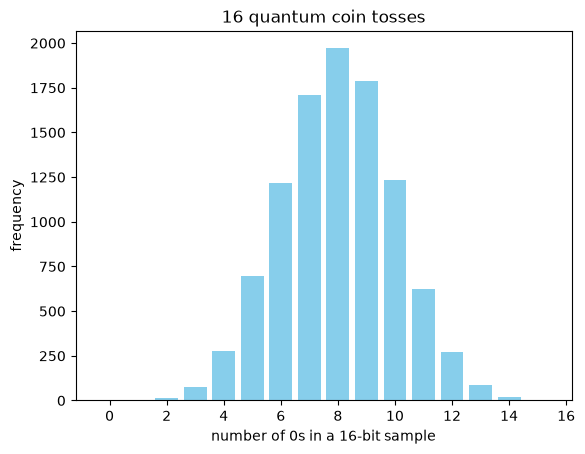

In [6]:
n = 16
qc = QuantumCircuit(n); qc.h(range(n))

samples = bq.run(qc, shots=10_000).get_counts()
zeros = Counter()

for bits, k in samples.items():
    zeros[bits.count("0")] += k
    
xs = sorted(zeros)

plt.bar(xs, [zeros[x] for x in xs], color="skyblue")
plt.xlabel("number of 0s in a 16-bit sample"); plt.ylabel("frequency"); plt.title("16 quantum coin tosses"); plt.show()

### ✏️ Exercise: shot noise

Estimate $\langle Z_0\rangle$ on the plus state from `shots` samples: +1 for each 0 on qubit 0,
-1 for each 1, averaged. The exact value is 0. Write `estimate_z0(shots)` (use
`bq.run(qc_plus, shots=shots).get_counts()`; qubit 0 is the **last** character of each key).
Then look at the printed table: the error should shrink roughly like $1/\sqrt{\text{shots}}$.

In [7]:
qc_plus = QuantumCircuit(1); qc_plus.h(0)

def estimate_z0(shots):
    counts = bq.run(qc_plus, shots=shots).get_counts()
    return sum((1 if bits[-1] == "0" else -1) * k for bits, k in counts.items()) / shots

# --- check (don't edit) ---
try:
    for s in (100, 10_000, 1_000_000):
        print(f"shots={s:>9,}  estimate={estimate_z0(s):+.4f}  typical error ~ {1/np.sqrt(s):.4f}")
    checks.truthy("estimate_z0 within 5 sigma at 1e6 shots", abs(estimate_z0(1_000_000)) < 5e-3,
                  hint="average +1/-1 over the shots")
except NotImplementedError:
    checks.truthy("estimate_z0", False, todo=True)

shots=      100  estimate=+0.0800  typical error ~ 0.1000
shots=   10,000  estimate=-0.0058  typical error ~ 0.0100
shots=1,000,000  estimate=-0.0002  typical error ~ 0.0010
✅ PASS  estimate_z0 within 5 sigma at 1e6 shots


## 3. GHZ on 40 qubits: beyond the statevector wall with MPS

A 40-qubit statevector needs $2^{40}\times16$ bytes ≈ 17.6 TB. A **matrix product state** stores one
small tensor per qubit instead, linked by bonds of size $\chi$ (the **bond dimension**). It's exact
as long as $\chi$ covers the entanglement across every cut of the chain.

The GHZ state $(|0\cdots0\rangle + |1\cdots1\rangle)/\sqrt2$ has only *one bit* of entanglement
across any cut, so $\chi = 2$ is exact, at any size.

In [8]:
def ghz(n, minus=False):
    qc = QuantumCircuit(n)
    if minus:
        qc.x(0)
    qc.h(0)
    for i in range(n - 1):
        qc.cx(i, i + 1)
    return qc

big = ghz(40)
try:
    bq.run(big)                       # the statevector simulator refuses: past the memory wall
except MemoryError as err:
    print("cpu refused:", err)

r = bq.run(big, device="mps.cpu", shots=1000, options={"mps_bond_dimension": 2})
print("MPS counts:", r.get_counts())

cpu refused: 40 qubits is past the statevector limit (26) of this machine: use mps.cpu or pauli-path
MPS counts: {'0000000000000000000000000000000000000000': 469, '1111111111111111111111111111111111111111': 531}


## 4. Expectation values tell apart states that counts can't

$(|0\cdots0\rangle + |1\cdots1\rangle)/\sqrt2$ and $(|0\cdots0\rangle - |1\cdots1\rangle)/\sqrt2$
give **identical** counts. But $\langle X X\cdots X\rangle$ is $+1$ for one and $-1$ for the other.
You ask for an expectation value with `pauli_sum`, a list of `(label, coefficient)` pairs.

In [9]:
obs = [("X" * 40, 1.0)]
for minus in (False, True):
    ev = bq.run(ghz(40, minus), device="mps.cpu", pauli_sum=obs, options={"mps_bond_dimension": 2}).expectation_value
    print(f"{'minus' if minus else 'plus '} GHZ:  <X...X> = {ev:+.3f}")

plus  GHZ:  <X...X> = +1.000
minus GHZ:  <X...X> = -1.000


### ✏️ Exercise: marginals vs correlations

For the 40-qubit GHZ state compute, with `device="mps.cpu"` and `mps_bond_dimension=2`:

- `z0`: $\langle Z_0\rangle$ (a single qubit's average). Use the helper `z_sum(q, n)`.
- `z0z39`: $\langle Z_0 Z_{39}\rangle$ (label with `Z` at both ends).

Before running: predict both. One-qubit averages miss what entanglement is about.

In [10]:
opts = {"mps_bond_dimension": 2}
z0 = bq.run(ghz(40), device="mps.cpu", pauli_sum=z_sum(0, 40), options=opts).expectation_value
z0z39 = bq.run(ghz(40), device="mps.cpu", pauli_sum=[("Z" + "I" * 38 + "Z", 1.0)], options=opts).expectation_value

# --- check (don't edit) ---
checks.close("<Z_0>", z0, 0.0, tol=1e-6, hint="each qubit alone is a fair coin")
checks.close("<Z_0 Z_39>", z0z39, 1.0, tol=1e-6, hint="the two ends always agree: both 0 or both 1")

✅ PASS  <Z_0>
✅ PASS  <Z_0 Z_39>


True

### ✏️ Exercise: why chi = 2 is enough: entanglement entropy

Cut a statevector of $n$ qubits into a left half and a right half: reshape it to a
$2^{n/2}\times 2^{n/2}$ matrix and take its singular values $s_i$. The **entanglement entropy**
is $S = -\sum_i s_i^2 \log_2 s_i^2$ bits, and an MPS needs about $\chi \approx 2^S$ there.

Write `half_entropy(psi)` and check: product state → 0 bits, GHZ → 1 bit (any $n$),
Bell pair → 1 bit. (Ignore $s_i^2 < 10^{-12}$ to avoid `log(0)`.)

In [11]:
def half_entropy(psi):
    n = int(np.log2(len(psi)))
    s2 = np.linalg.svd(np.asarray(psi).reshape(2 ** (n // 2), -1), compute_uv=False) ** 2
    s2 = s2[s2 > 1e-12]
    return float(-(s2 * np.log2(s2)).sum())

# --- check (don't edit) ---
sv = lambda qc: bq.run(qc).get_statevector()
prod = QuantumCircuit(6); prod.h(range(6))
bell = QuantumCircuit(2); bell.h(0); bell.cx(0, 1)
checks.fn("half_entropy", half_entropy,
          [((sv(prod),), 0.0), ((sv(ghz(6)),), 1.0), ((sv(ghz(10)),), 1.0), ((sv(bell),), 1.0)], tol=1e-6)

✅ PASS  half_entropy  - 4 test cases


True

## Recap

- `bq.run(qc, shots=N)` → counts (samples); no shots → statevector; `pauli_sum=[...]` → expectation value.
- Qubit 0 is the **rightmost** character in bitstrings and Pauli labels.
- Shot noise shrinks like $1/\sqrt N$.
- Statevectors hit a memory wall in the mid-30s of qubits. MPS gets past it **when entanglement is low**:
  $\chi \approx 2^{S}$ for entropy $S$ across the worst cut.

**Next:** `02_choosing_a_simulator.ipynb`: when does each simulator work, and how do you know you can trust it?